INFO       No numerical integration method specified for group 'synapses_3', using method 'exact' (took 0.00s). [brian2.stateupdaters.base.method_choice]


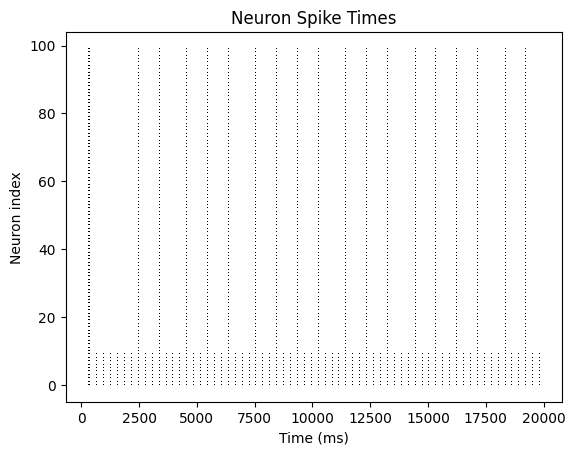

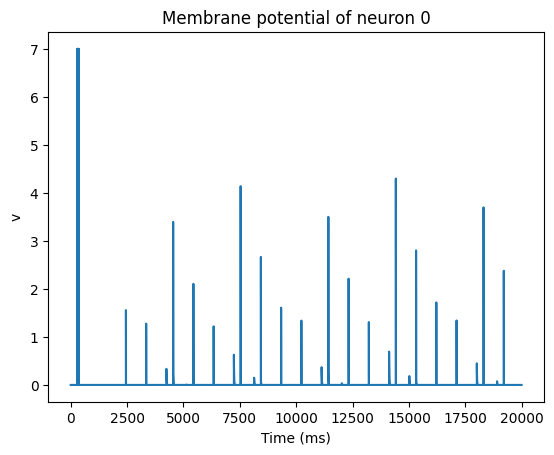

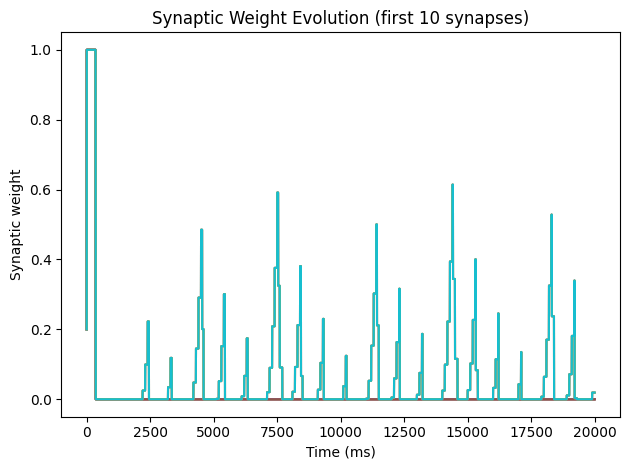

In [49]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

# Parameters
tau = 10*ms
refractory_period = 5*ms
tau_homeo = 10000*ms
target_firing_rate = 10 #*Hz
alpha = 0.5

# Neuron model (LIF)
eqs_neurons = '''
dv/dt = (I - v) / tau : 1
I : 1
'''

N = 100
neurons = NeuronGroup(N, eqs_neurons, threshold='v > 1', reset='v = 0',
                      refractory=refractory_period, method='exact')
neurons.I = 0  
neurons.I[:10] = 1.0000000000001  


# Synapse model with dynamic variable
eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
w : 1
'''

# Synapses
synapses = Synapses(neurons, neurons, model=eqs_syn,
    on_pre='v_post += w',
    on_post='''
        synaptic_activity += 1
        firing_rate_diff = target_firing_rate - synaptic_activity #/ second  
        w += alpha * firing_rate_diff
        w = clip(w, 0, 1)
''')

synapses.connect(p=0.5)
synapses.w = 0.2 #'rand()'
synapses.synaptic_activity = 0

# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=10)
weight_mon = StateMonitor(synapses, 'w', record=range(100))  # Track weights of first 100 synapses

# Run
# Add after defining synapses:
synapses.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, 1)
''', dt=100*ms)
run(20*second)

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0])
plt.title('Membrane potential of neuron 0')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(10, len(weight_mon.w))):  # Plot only a few synapses for clarity
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')

plt.tight_layout()
plt.show()

WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
INFO       No numerical integration method specified for group 'synapses', using method 'exact' (took 0.00s). [brian2.stateupdaters.base.method_choice]


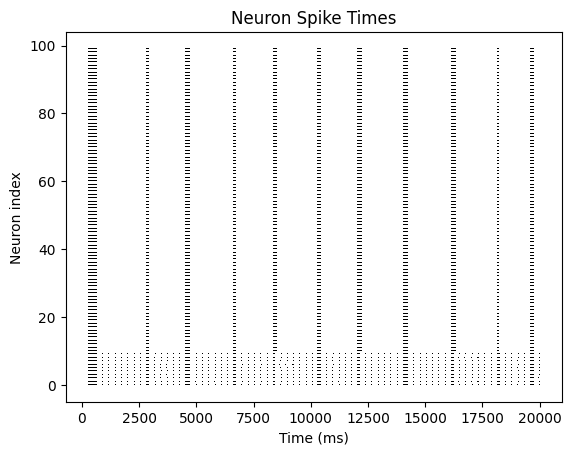

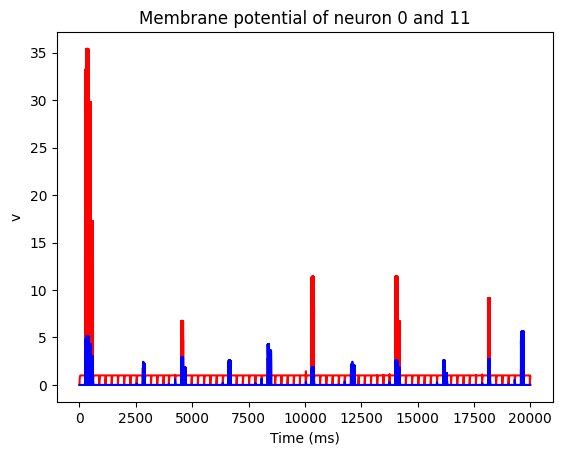

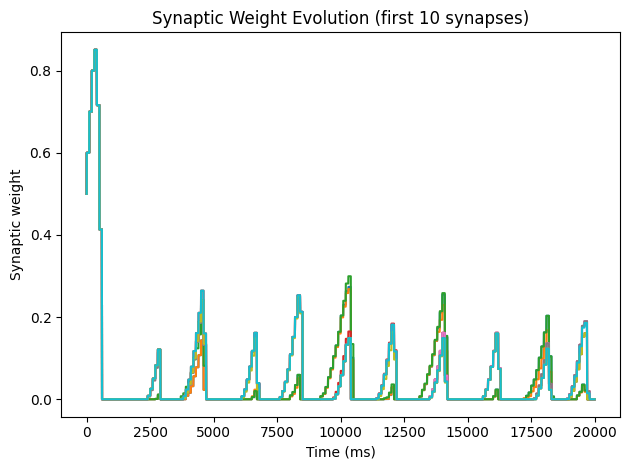

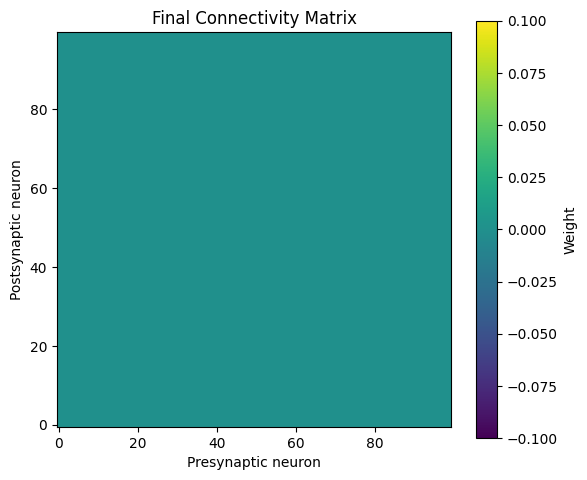

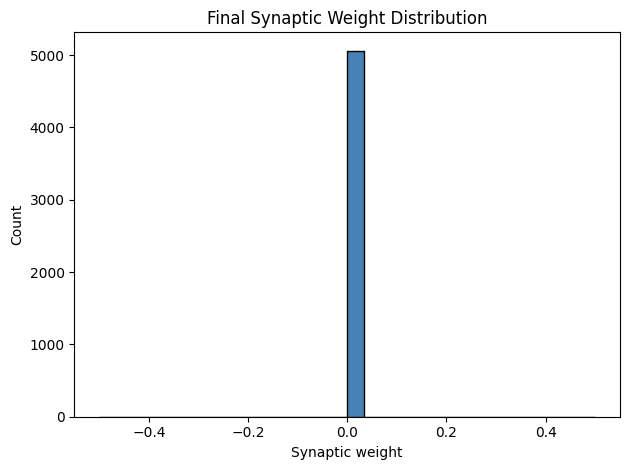

In [56]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

# Parameters
tau = 10*ms
refractory_period = 5*ms
tau_homeo = 1000*ms
target_firing_rate = 10 #*Hz
alpha = 0.01

# Neuron model (LIF)
eqs_neurons = '''
dv/dt = (I - v) / tau : 1
I : 1
'''

N = 100
neurons = NeuronGroup(N, eqs_neurons, threshold='v > 1', reset='v = 0',
                      refractory=refractory_period, method='exact')
neurons.I = 0  
neurons.I[:10] = 1.000000000001  


# Synapse model with dynamic variable
eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_activity/dt = -pre_activity / tau_homeo : 1 (clock-driven)
w : 1
'''

# Synapses
synapses = Synapses(neurons, neurons, model=eqs_syn,
    on_pre='''
        v_post += w
        pre_activity += 1
    ''',
    on_post='''
        synaptic_activity += 1
    '''
)

synapses.connect(p=0.5)
synapses.w = 0.5 #'0.5 + 0.2*rand()'
synapses.synaptic_activity = 0
synapses.pre_activity = 0

synapses.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, 1)
''', dt=100*ms)

# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0,11])
weight_mon = StateMonitor(synapses, 'w', record=range(100))  


run(20*second)

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0],color='red')
plt.plot(statemon.t/ms, statemon.v[1],color='blue')
plt.title('Membrane potential of neuron 0 and 11')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(10, len(weight_mon.w))):  # Plot only a few synapses for clarity
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')

plt.tight_layout()
plt.show()

# Final connectivity matrix
plt.figure(figsize=(6, 5))
conn_matrix = np.zeros((N, N))
for i, j, w in zip(synapses.i[:], synapses.j[:], synapses.w[:]):
    conn_matrix[i, j] = w
plt.imshow(conn_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

# Final weight histogram
plt.figure()
plt.hist(synapses.w[:], bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()

WARNING    'w' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value 0.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
INFO       No numerical integration method specified for group 'synapses_1', using method 'exact' (took 0.00s). [brian2.stateupdaters.base.method_choice]


Starting simulation at t=0. s for a duration of 1. ks
18.0558 s (1%) simulated in 10s, estimated 9m 4s remaining.
43.6162 s (4%) simulated in 20s, estimated 7m 19s remaining.
69.7813 s (6%) simulated in 30s, estimated 6m 40s remaining.
96.3991 s (9%) simulated in 40s, estimated 6m 15s remaining.
131.6423 s (13%) simulated in 50s, estimated 5m 30s remaining.
159.9505 s (15%) simulated in 1m 0s, estimated 5m 15s remaining.
186.3694 s (18%) simulated in 1m 10s, estimated 5m 6s remaining.
219.0013 s (21%) simulated in 1m 20s, estimated 4m 45s remaining.
244.1885 s (24%) simulated in 1m 30s, estimated 4m 39s remaining.
272.8451 s (27%) simulated in 1m 40s, estimated 4m 27s remaining.
306.4827 s (30%) simulated in 1m 50s, estimated 4m 9s remaining.
0.3351515 ks (33%) simulated in 2m 0s, estimated 3m 58s remaining.
0.3595272 ks (35%) simulated in 2m 10s, estimated 3m 52s remaining.
0.3951274 ks (39%) simulated in 2m 20s, estimated 3m 34s remaining.
0.4211556 ks (42%) simulated in 2m 30s, esti

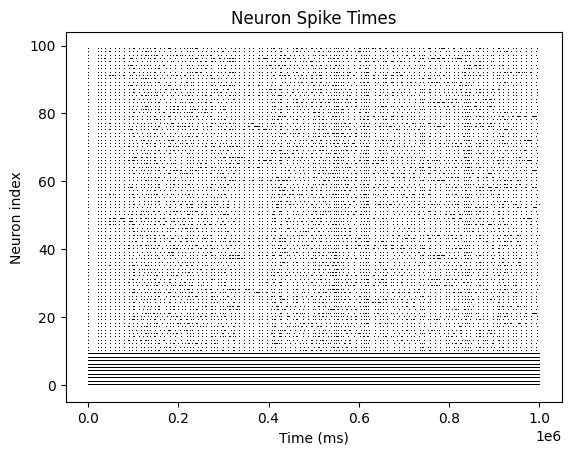

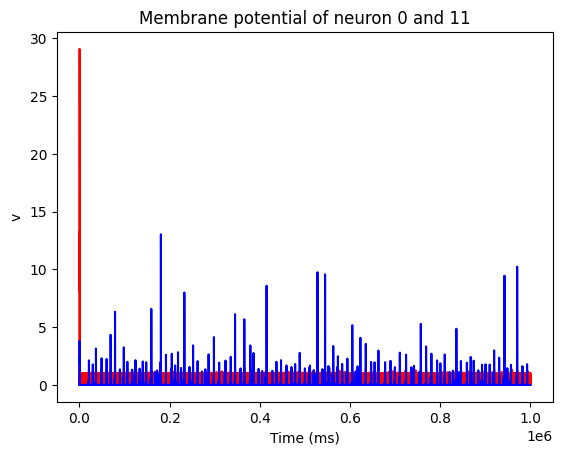

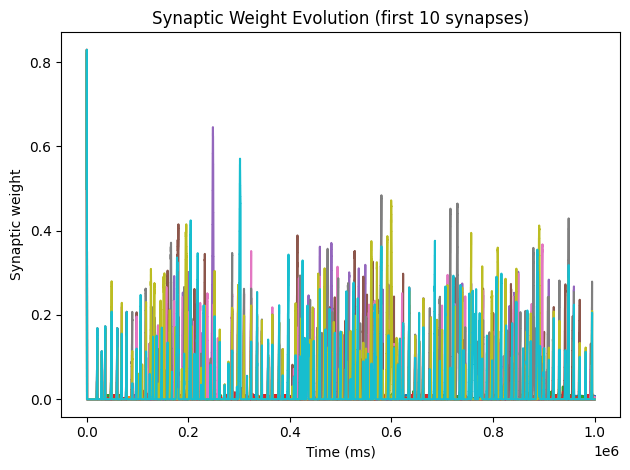

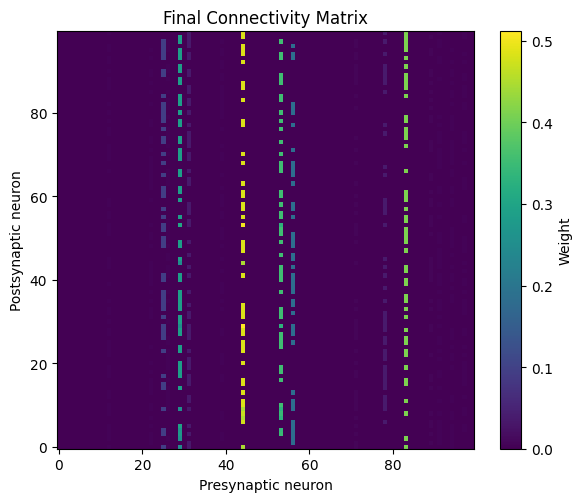

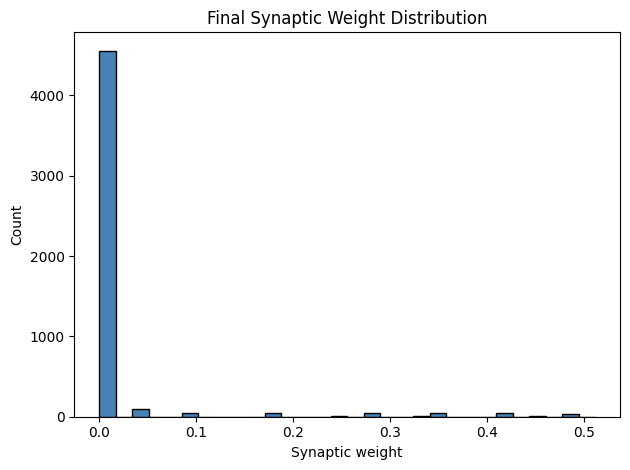

In [6]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

time_simu = 1000*second
tau = 10*ms
refractory_period = 5*ms
tau_homeo = 10*second
target_firing_rate = 10 #*Hz
alpha = 0.01

eqs_neurons = '''
dv/dt = (I - v) / tau : 1
I : 1
'''

N = 100
neurons = NeuronGroup(N, eqs_neurons, threshold='v > 1', reset='v = 0',
                      refractory=refractory_period, method='exact')
neurons.I = 0  
neurons.I[:10] = 1.000000000001  


eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_trace/dt = -pre_trace / tau_pre : 1 (clock-driven)
dpost_trace/dt = -post_trace / tau_post : 1 (clock-driven)
w : 1
'''


A_plus = 0.01  # potentiation amplitude
A_minus = 0.012  # depression amplitude 
tau_pre = 20*ms
tau_post = 20*ms

synapses = Synapses(neurons, neurons, model=eqs_syn,
    on_pre='''
        v_post += w
        pre_trace = 1
        w += A_plus * post_trace
        w = clip(w, 0, 1)
    ''',
    on_post='''
        post_trace = 1
        w -= A_minus * pre_trace
        w = clip(w, 0, 1)
        synaptic_activity += 1
    '''
)
#,namespace={'A_plus': A_plus, 'A_minus': A_minus, 'tau_pre': tau_pre, 'tau_post': tau_post, 'tau_homeo': tau_homeo}

synapses.connect(p=0.5)
synapses.w = 0.5 #'0.5 + 0.2*rand()'
synapses.synaptic_activity = 0

synapses.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, 1)
''', dt=100*ms)

# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0,11])
weight_mon = StateMonitor(synapses, 'w', record=range(10))  #100
rate_mon = PopulationRateMonitor(neurons)



run(duration=time_simu, report = 'text')

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0],color='red')
plt.plot(statemon.t/ms, statemon.v[1],color='blue')
plt.title('Membrane potential of neuron 0 and 11')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(10, len(weight_mon.w))):  # Plot only a few synapses for clarity
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')

plt.tight_layout()
plt.show()

# Final connectivity matrix
plt.figure(figsize=(6, 5))
conn_matrix = np.zeros((N, N))
for i, j, w in zip(synapses.i[:], synapses.j[:], synapses.w[:]):
    conn_matrix[i, j] = w
plt.imshow(conn_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

# Final weight histogram
plt.figure()
plt.hist(synapses.w[:], bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()

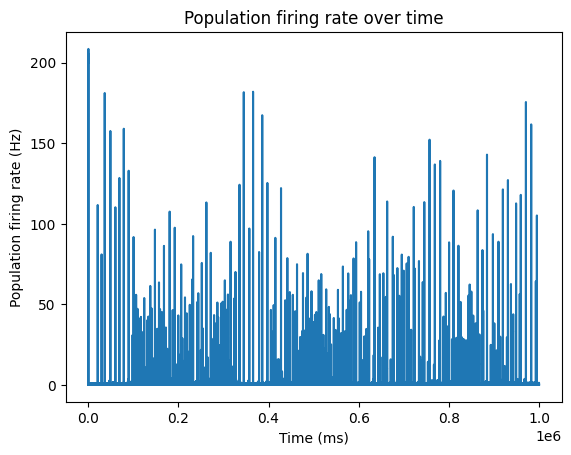

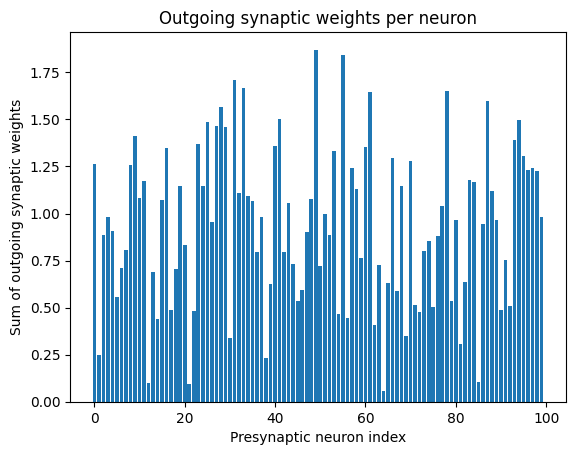

In [7]:
plt.figure()
plt.plot(rate_mon.t/ms, rate_mon.smooth_rate(window='flat', width=100*ms)/Hz)
plt.xlabel('Time (ms)')
plt.ylabel('Population firing rate (Hz)')
plt.title('Population firing rate over time')
plt.show()

outgoing_w = np.zeros(N)
for i, j, w in zip(synapses.i[:], synapses.j[:], synapses.w[:]):
    outgoing_w[i] += w
plt.figure()
plt.bar(np.arange(N), outgoing_w)
plt.xlabel('Presynaptic neuron index')
plt.ylabel('Sum of outgoing synaptic weights')
plt.title('Outgoing synaptic weights per neuron')
plt.show()


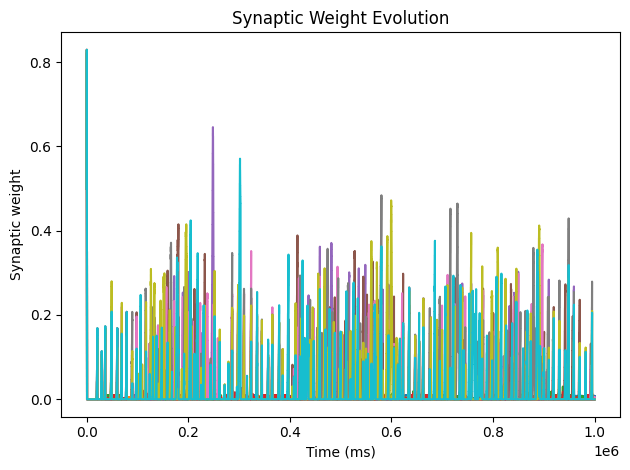

In [8]:
import matplotlib.pyplot as plt
plt.figure()
for i in range(min(100, len(weight_mon.w))):  
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution')

plt.tight_layout()
plt.show()

In [ ]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np
import imageio
import os

start_scope()

# Parameters
time_simu = 10*second
save_interval = 0.01*second   
tau = 10*ms
refractory_period = 5*ms
tau_homeo = 1*second
target_firing_rate = 10
alpha = 0.1

eqs_neurons = '''
dv/dt = (I - v) / tau : 1
I : 1
'''

N = 100
neurons = NeuronGroup(N, eqs_neurons, threshold='v > 1', reset='v = 0',
                      refractory=refractory_period, method='exact')
neurons.I = 0
neurons.I[:10] = 1.000000000001

eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_trace/dt = -pre_trace / tau_pre : 1 (clock-driven)
dpost_trace/dt = -post_trace / tau_post : 1 (clock-driven)
w : 1
'''

A_plus = 0.01
A_minus = 0.012
tau_pre = 20*ms
tau_post = 20*ms

synapses = Synapses(neurons, neurons, model=eqs_syn,
    on_pre='''
        v_post += w
        pre_trace = 1
        w += A_plus * post_trace
        w = clip(w, 0, 1)
    ''',
    on_post='''
        post_trace = 1
        w -= A_minus * pre_trace
        w = clip(w, 0, 1)
        synaptic_activity += 1
    '''
)

synapses.connect(p=0.5)
synapses.w = 0.5
synapses.synaptic_activity = 0

synapses.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, 1)
''', dt=100*ms)

# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0, 11])
weight_mon = StateMonitor(synapses, 'w', record=range(10))
rate_mon = PopulationRateMonitor(neurons)

n_saves = int(time_simu / save_interval)
conn_matrices = []
image_files = []

for snap in range(n_saves):
    run(save_interval)
    conn_matrix = np.zeros((N, N))
    for i, j, w in zip(synapses.i[:], synapses.j[:], synapses.w[:]):
        conn_matrix[i, j] = w
    conn_matrices.append(conn_matrix.copy())
    # Plot and save image
    plt.figure(figsize=(5, 4))
    plt.imshow(conn_matrix, cmap='viridis', origin='lower', vmin=0, vmax=1)
    plt.colorbar(label='Weight')
    plt.title(f'Connectivity at t={((snap+1)*float(save_interval/second)):.0f}s')
    plt.xlabel('Presynaptic neuron')
    plt.ylabel('Postsynaptic neuron')
    plt.tight_layout()
    img_name = f'conn_matrix_{snap:03d}.png'
    plt.savefig(img_name)
    plt.close()
    image_files.append(img_name)

# Make gif
with imageio.get_writer('connectivity_evolution.gif', mode='I', duration=5.0) as writer:
    for filename in image_files:
        image = imageio.imread(filename)
        writer.append_data(image)

# Optional: Remove PNGs to save space
for fname in image_files:
    os.remove(fname)

print("GIF saved as connectivity_evolution.gif")

# ----------- Regular plots (optional, after main run) -----------
# You can skip this block if you only want the gif

plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0], color='red')
plt.plot(statemon.t/ms, statemon.v[1], color='blue')
plt.title('Membrane potential of neuron 0 and 11')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

plt.figure()
for i in range(min(10, len(weight_mon.w))):
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
final_matrix = conn_matrices[-1]
plt.imshow(final_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

plt.figure()
plt.hist(synapses.w[:], bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()


WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 1.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.988. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.9795760156614282. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.9711520313228563. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.9837880078307141. 